# S2 v1 STAR — IS diagnosis (sealed OOS off-limits)

Failure forensics on the **frozen** Universe STAR using **research IS only** (`date <= RESEARCH_IS_END`).

Run this notebook before H-009 as to understand if this strategy and its chosen universe does contain edge or not, before tuning parameters in later stages. This is to avoid bias by overfitting.

**Do not** load, plot, or filter sealed OOS here. Disposition after this notebook is kill / paper / new H — never re-tune on the sealed slice.

Check excess kurtosis, pair concentration, cost drag, ADF health, and zero-volume skips **before** opening `02_oos_tearsheet.ipynb`.


## 0. Imports & Config


In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "01_data", "ingestion")):
    parent = os.path.dirname(ROOT)
    if parent == ROOT:
        break
    ROOT = parent
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from backtest.s2_coint.diagnosis import (
    check_fill_timing,
    enrich_trades,
    extreme_trades,
    gross_returns_from_net,
    plotly_pair_diagnosis,
    print_extreme_trades,
    zero_volume_skip_table,
)
from backtest.s2_coint.report import fold_val_metrics, load_star_stack, require_star
from backtest.s2_coint.research import (
    DEFAULT_STAR_STACK,
    config_from_stack,
    frozen_pairs_for_universe,
    is_end_for_stack,
    load_s1_weekly,
    load_star_panels,
    load_universe_panels,
    lookbacks_for_bar,
    n_trials_ledger_total,
    overlay_kalman_hedge,
    overlay_ols_hedge,
    split_is_oos,
)
from backtest.s2_coint.runner import run_s2_backtest
from backtest.s2_coint.tearsheet import (
    baseline_configs_from_star,
    cost_stress_oos_sharpes,
    daily_regime_performance,
    early_late_is_decay,
    fit_mean_abs_score,
    oos_headline_metrics,
    pair_concentration,
    pair_pnl_attribution,
    pair_scorecard,
    plot_drawdown,
    plot_equity_net_gross,
    reversion_health_table,
    spy_daily_returns,
    utilization_stats,
)
from backtest.s2_coint.walkforward import embargo_bars_for_config, make_s2_folds
from strategies.s2_coint.metrics import metrics_from_returns

stack = load_star_stack(DEFAULT_STAR_STACK)
require_star("UNIVERSE_STAR", stack.get("UNIVERSE_STAR"))
require_star("BAR_STAR", stack.get("BAR_STAR"))
UNIVERSE = str(stack["UNIVERSE_STAR"])
BAR = str(stack.get("BAR_STAR") or "1d")
PAIRS = stack.get("PAIRS_STAR")
if not PAIRS:
    PAIRS = frozen_pairs_for_universe(UNIVERSE, BAR, root=ROOT)
N_STACK = n_trials_ledger_total()
print("BANNER: IS-only diagnosis — sealed OOS is off-limits")
print(DEFAULT_STAR_STACK)
print(f"UNIVERSE={UNIVERSE}  BAR={BAR}  n_trials_stack={N_STACK}")
print("PAIRS", PAIRS)
display(pd.Series(stack, name="value").to_frame())


BANNER: IS-only diagnosis — sealed OOS is off-limits
C:\Users\User\Desktop\ML Algorithmic Trading\Portfolio 26\trading_portfolio\04_backtest\s2_coint\artifacts\v1\s2_star_stack.json
UNIVERSE=E  BAR=1d  n_trials_stack=55
PAIRS ['CCI|AMT', 'SBRA|VTR', 'NNN|O', 'NNN|WPC', 'PLD|TRNO']


,value
UNIVERSE_STAR,E
BAR_STAR,1d
PAIRS_STAR,"[CCI|AMT, SBRA|VTR, NNN|O, NNN|WPC, PLD|TRNO]"
BREAK_STAR,block_05_flat_10
BOOK_STAR,freeze
OLS_WINDOW_STAR,504
ADF_WINDOW_STAR,252
ENTRY_Z_STAR,1.5
Z_WINDOW_STAR,90
HEDGE_STAR,kalman


## 1. Contract


In [2]:
print("Timing: signal at close t → fill both legs open t+1 (S2 contract)")
print("Hedge / z / ADF / half-life use close_y / close_x only")
print(f"Universe {UNIVERSE}  bar {BAR}  cost_profile={stack.get('COST_PROFILE_STAR') or 'venue default'}")
print("Disposition from this notebook: kill / paper / new H — never re-tune on sealed OOS")


Timing: signal at close t → fill both legs open t+1 (S2 contract)
Hedge / z / ADF / half-life use close_y / close_x only
Universe E  bar 1d  cost_profile=venue default
Disposition from this notebook: kill / paper / new H — never re-tune on sealed OOS


## 2. Run frozen STAR on IS only


In [3]:
try:
    train, full, manifest = load_star_panels(
        universe=UNIVERSE, bar=BAR, pair_ids=PAIRS, root=ROOT
    )
    print("loaded star panels", manifest.get("stack_hash"))
except (FileNotFoundError, ValueError) as exc:
    warnings.warn(f"star panels unavailable ({exc}); overlaying hedge from census panel")
    train, full = load_universe_panels(UNIVERSE, BAR, PAIRS, root=ROOT)
    lb = lookbacks_for_bar(
        BAR,
        ols_days=int(stack["OLS_WINDOW_STAR"])
        if stack.get("OLS_WINDOW_STAR") not in (None, "")
        else None,
        z_days=int(stack["Z_WINDOW_STAR"])
        if stack.get("Z_WINDOW_STAR") not in (None, "")
        else None,
        adf_days=int(stack["ADF_WINDOW_STAR"])
        if stack.get("ADF_WINDOW_STAR") not in (None, "")
        else None,
    )
    train = overlay_ols_hedge(
        train,
        ols_window=lb["ols_window"],
        z_window=lb["z_window"],
        hl_window=lb["hl_window"],
        adf_window=lb["adf_window"],
    )
    full = overlay_ols_hedge(
        full,
        ols_window=lb["ols_window"],
        z_window=lb["z_window"],
        hl_window=lb["hl_window"],
        adf_window=lb["adf_window"],
    )
    if stack.get("HEDGE_STAR") == "kalman":
        kf_delta = stack.get("KALMAN_DELTA_STAR") or 1e-4
        train = overlay_kalman_hedge(
            train,
            burn_in=lb["kalman_burn_in"],
            z_window=lb["z_window"],
            hl_window=lb["hl_window"],
            adf_window=lb["adf_window"],
            delta=float(kf_delta),
        )
        full = overlay_kalman_hedge(
            full,
            burn_in=lb["kalman_burn_in"],
            z_window=lb["z_window"],
            hl_window=lb["hl_window"],
            adf_window=lb["adf_window"],
            delta=float(kf_delta),
        )

IS_END = is_end_for_stack(stack, full)
panel_is, _oos_unused = split_is_oos(full, is_end=IS_END)
del _oos_unused
assert (pd.to_datetime(panel_is["date"]) > pd.Timestamp(IS_END)).sum() == 0, (
    "OOS rows leaked into IS panel"
)

cfg = config_from_stack(stack)
mean_abs = fit_mean_abs_score(panel_is, score_column=cfg.score_column)
s1_weekly = load_s1_weekly(ROOT)
if s1_weekly is None or getattr(s1_weekly, "empty", True):
    warnings.warn("S1 period returns missing — corr_to_s1 will be NaN")
    s1_weekly = pd.Series(dtype=float)
spy = spy_daily_returns(panel_is["date"].min(), panel_is["date"].max())

res = run_s2_backtest(
    panel_is,
    cfg,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    mean_abs_score=mean_abs,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
is_net = res.returns
is_gross = res.book.returns_gross
if is_gross is None or getattr(is_gross, "empty", True):
    is_gross = gross_returns_from_net(is_net, res.pair_trades)
print("IS end", IS_END.date(), "bars", len(panel_is), "return days", len(is_net))
print("mean_abs_score", round(float(mean_abs), 4), "cost_profile", cfg.cost_profile)
print(cfg)


C:\Users\User\AppData\Local\Temp\ipykernel_880\2773100133.py:7: UserWarning: star panels unavailable (missing c:\Users\User\Desktop\ML Algorithmic Trading\Portfolio 26\trading_portfolio\01_data\data_files\s2_coint\s2_panel_E_1d_train_star.parquet. Run build_star_panels.ipynb after H-005/H-006 freeze.); overlaying hedge from census panel
  warnings.warn(f"star panels unavailable ({exc}); overlaying hedge from census panel")


IS end 2021-12-31 bars 26732 return days 6851
mean_abs_score 0.964 cost_profile None
S2SimConfig(hedge='kalman', bar='1d', entry_z=1.5, exit_z=0.0, k_in=2.0, k_out=0.0, beta_column='beta', score_column='z', use_hedge_ratio_sizing=True, ols_window=504, z_window=90, hl_window=252, adf_window=252, break_mode='block_05_flat_10', trend_mode='adx_veto', hl_gate_min=None, hl_gate_max=None, overlap_mode='allow', atr_stop_mult=None, hl_exit_n=None, atr_risk_frac=0.01, pair_max_loss=-0.1, atr_window=14, corr_k=None, size_mode='equal', vol_mode='s1_vt', k0=2.0, sigma_window=60, sigma_bar=None, vt_target_ann_vol=0.06, z_window_mode='fixed', z_clip_min=20, z_clip_max=120, entry_mode='trad_z', hmm_mr_threshold=0.5, cost_profile=None)


## 3. Headline IS metrics (gross vs net)


,IS
ann_sharpe_net,0.554474
ann_sharpe_gross,0.672583
sortino,0.863986
calmar,0.198580
max_drawdown,-0.110024
cagr,0.021849
total_return,0.799647
psr,0.998522
dsr_local,0.998522
dsr_stack,0.723922


C:\Users\User\AppData\Local\Temp\ipykernel_880\2676067222.py:13: UserWarning: IS excess kurtosis 39.16 — inspect a single pair before OOS
  warnings.warn(


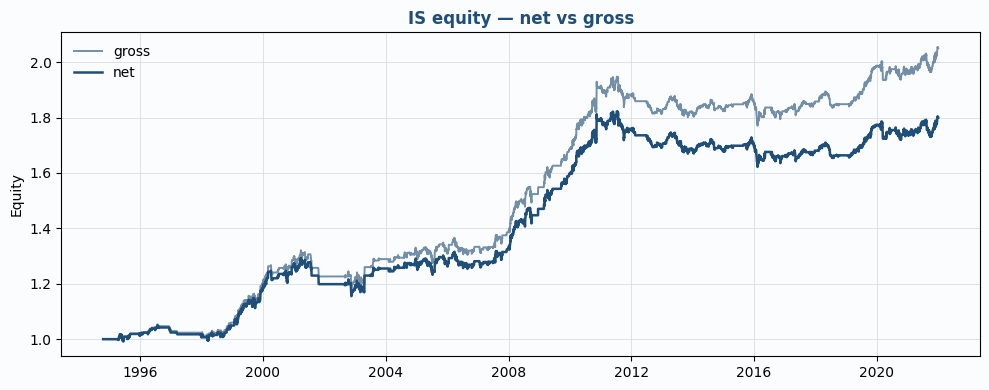

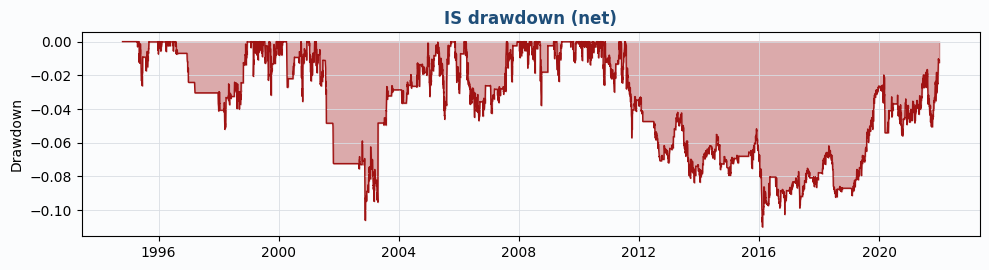

In [4]:
headline = oos_headline_metrics(
    is_net,
    is_gross,
    trades=res.pair_trades,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    spy_daily=spy if not spy.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
display(headline.to_frame("IS"))
excess = float(headline.get("excess_kurtosis", float("nan")))
if np.isfinite(excess) and excess > 8:
    warnings.warn(
        f"IS excess kurtosis {excess:.2f} — inspect a single pair before OOS"
    )
fig = plot_equity_net_gross(is_net, is_gross, title="IS equity — net vs gross")
plt.show()
fig = plot_drawdown(is_net, title="IS drawdown (net)")
plt.show()


## 4. Fold-val consistency + early/late IS decay


In [5]:
is_dates = pd.DatetimeIndex(panel_is["date"].drop_duplicates().sort_values())
folds = make_s2_folds(
    is_dates,
    n_folds=3,
    embargo_bars=embargo_bars_for_config(bar=str(cfg.bar)),
)
fold_df = fold_val_metrics(
    panel_is,
    folds,
    {"frozen_star": cfg},
    hyp_id=None,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
)
display(fold_df)
decay = early_late_is_decay(is_net)
display(decay.to_frame("value"))


,arm,fold_id,ann_sharpe,max_drawdown,corr_to_s1,psr,dsr_local,dsr_stack,n_trials_local,n_trials_stack,n_days,n_entries,pct_z_finite,median_hl_bars,median_hl_sessions
0,frozen_star,1,0.494574,-0.064053,NaN,0.905190,NaN,NaN,None,None,1713,76,0.982207,9.306813,9.306813
1,frozen_star,2,0.595203,-0.083741,NaN,0.952193,NaN,NaN,None,None,1713,96,0.985370,9.667998,9.667998
2,frozen_star,3,0.288661,-0.061466,-0.089997,0.773571,NaN,NaN,None,None,1713,119,1.000000,9.163552,9.163552


,value
early_sharpe,0.639319
late_sharpe,0.461599
decay_ratio,0.722017
n_early,3426.0
n_late,3425.0
midpoint,2008-05-27


## 5. Pair scorecard + attribution (IS)


,pair_id,ann_sharpe_net,ann_sharpe_gross,max_drawdown,n_trades,cost_bps_year,pct_adf_lt_05,n_days
0,NNN|O,0.447833,0.523004,-0.165104,89,43.225230,45.235921,6849
2,CCI|AMT,0.432709,0.489816,-0.233251,86,48.643156,58.943235,5881
4,PLD|TRNO,0.403993,0.506869,-0.107358,49,54.458269,59.985262,2993
1,NNN|WPC,0.318977,0.375821,-0.274766,86,47.472685,48.477467,6026
3,SBRA|VTR,0.208544,0.236463,-0.299034,55,36.789061,43.161483,4973


,is_total_return
PLD|TRNO,0.268119
SBRA|VTR,0.467808
NNN|WPC,0.735083
NNN|O,0.923785
CCI|AMT,1.170038


,value
n_pairs,5.0
max_pair_share,0.328217
max_pair_id,CCI|AMT
hhi_abs,0.240277


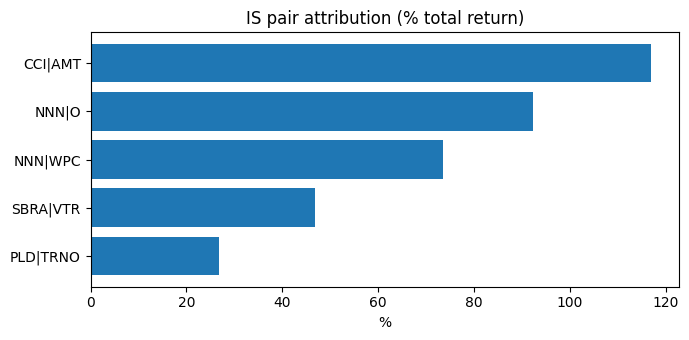

,pair_id,window,pct_adf_lt_threshold,median_half_life,beta_std,n_days
0,NNN|O,IS,45.235921,9.117965,0.226803,6851
1,NNN|WPC,IS,48.477467,8.504656,0.089933,6028
2,CCI|AMT,IS,58.943235,8.443998,0.119293,5883
3,SBRA|VTR,IS,43.161483,11.252161,1.051560,4975
4,PLD|TRNO,IS,59.985262,8.402013,0.231833,2995


=== Best 5 trades by net pnl_pct ===
 pair_id side_label entry_date  exit_date   pnl_pct   z_entry
SBRA|VTR       long 2003-04-04 2003-04-24 35.716251 -2.065449
SBRA|VTR      short 2002-12-26 2003-01-24 13.456160  1.785798
 NNN|WPC      short 2009-02-25 2009-03-17 12.397109  1.583147
 CCI|AMT       long 2000-03-01 2000-03-03 11.020441 -1.606236
 CCI|AMT       long 1999-04-06 1999-04-20 10.880145 -2.206141

=== Worst 5 trades by net pnl_pct ===
 pair_id side_label entry_date  exit_date    pnl_pct   z_entry
SBRA|VTR       long 2003-01-27 2003-03-18 -15.318220 -1.925065
SBRA|VTR       long 2011-07-21 2011-10-13 -15.088997 -2.340667
 CCI|AMT       long 2001-07-20 2001-08-02 -12.438810 -1.867082
 CCI|AMT      short 2001-10-22 2001-10-29  -8.205580  1.752834
 NNN|WPC      short 2012-06-29 2012-09-11  -7.983475  2.224990


,pair_id,side,side_label,entry_date,exit_date,hold_bars,entry_cost_bps,exit_cost_bps,exit_reason,signal_date,exit_signal_date,z_entry,z_exit,spread_entry,spread_exit,adf_entry,adf_exit,pnl_pct
0,SBRA|VTR,1,long,2003-04-04,2003-04-24,13,6.6,6.6,mean_revert,2003-04-03,2003-04-23,-2.065449,1.991940,-1.490121,-0.176862,NaN,NaN,35.716251
1,SBRA|VTR,-1,short,2002-12-26,2003-01-24,19,6.6,6.6,mean_revert,2002-12-24,2003-01-23,1.785798,-1.424619,-0.222812,-0.830790,NaN,NaN,13.456160
2,NNN|WPC,-1,short,2009-02-25,2009-03-17,14,6.6,6.6,mean_revert,2009-02-24,2009-03-16,1.583147,-0.358377,0.096267,-0.108309,0.027444,0.028626,12.397109
3,CCI|AMT,1,long,2000-03-01,2000-03-03,2,6.6,6.6,mean_revert,2000-02-29,2000-03-02,-1.606236,0.485914,-0.200292,0.046019,0.006222,0.002337,11.020441
4,CCI|AMT,1,long,1999-04-06,1999-04-20,10,6.6,6.6,mean_revert,1999-04-05,1999-04-19,-2.206141,0.452184,-0.082884,0.161250,NaN,NaN,10.880145


,pair_id,side,side_label,entry_date,exit_date,hold_bars,entry_cost_bps,exit_cost_bps,exit_reason,signal_date,exit_signal_date,z_entry,z_exit,spread_entry,spread_exit,adf_entry,adf_exit,pnl_pct
0,SBRA|VTR,1,long,2003-01-27,2003-03-18,35,6.6,6.6,mean_revert,2003-01-24,2003-03-17,-1.925065,0.393787,-0.943599,-0.667749,NaN,NaN,-15.318220
1,SBRA|VTR,1,long,2011-07-21,2011-10-13,59,6.6,6.6,mean_revert,2011-07-20,2011-10-12,-2.340667,0.009506,-0.094442,-0.101073,0.006678,0.013915,-15.088997
2,CCI|AMT,1,long,2001-07-20,2001-08-02,9,6.6,6.6,coint_break,2001-07-19,2001-08-01,-1.867082,-2.714732,-0.216641,-0.369637,0.006630,0.128817,-12.438810
3,CCI|AMT,-1,short,2001-10-22,2001-10-29,5,6.6,6.6,coint_break,2001-10-19,2001-10-26,1.752834,2.362508,0.164429,0.301639,0.041590,0.202036,-8.205580
4,NNN|WPC,-1,short,2012-06-29,2012-09-11,50,6.6,6.6,coint_break,2012-06-28,2012-09-10,2.224990,1.869004,0.041338,0.073725,0.003927,0.116078,-7.983475


In [6]:
score = pair_scorecard(res.book.pair_results, panel_is, date_max=IS_END)
attr = pair_pnl_attribution(res.book.pair_results, date_max=IS_END)
conc = pair_concentration(attr)
display(score.sort_values("ann_sharpe_net", ascending=False))
display(attr.to_frame("is_total_return"))
display(conc.to_frame("value"))
if np.isfinite(float(conc.get("max_pair_share", float("nan")))) and float(
    conc["max_pair_share"]
) > 0.5:
    warnings.warn(
        f"IS PnL concentrated in {conc['max_pair_id']} "
        f"({100.0 * float(conc['max_pair_share']):.1f}% of |contribution|)"
    )

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(list(attr.index), 100.0 * attr.values)
ax.set_title("IS pair attribution (% total return)")
ax.set_xlabel("%")
plt.tight_layout()
plt.show()

health = reversion_health_table(panel_is, is_end=IS_END)
display(health.loc[health["window"] == "IS"].reset_index(drop=True))

enriched_parts = []
for pid, pr in res.book.pair_results.items():
    g = panel_is.loc[panel_is["pair_id"].astype(str) == str(pid)]
    enriched_parts.append(enrich_trades(pr.trades, g, pr.returns))
trades_enriched = (
    pd.concat(enriched_parts, ignore_index=True)
    if enriched_parts
    else pd.DataFrame()
)
print_extreme_trades(trades_enriched, n=5)
best, worst = extreme_trades(trades_enriched, n=5)
display(best)
display(worst)

focus = str(conc.get("max_pair_id") or "")
if not focus and not attr.empty:
    focus = str(attr.index[0])
if focus:
    g = panel_is.loc[panel_is["pair_id"].astype(str) == focus]
    t = (
        trades_enriched.loc[trades_enriched["pair_id"].astype(str) == focus]
        if not trades_enriched.empty
        else trades_enriched
    )
    pr = res.book.pair_results.get(focus)
    fig = plotly_pair_diagnosis(
        g,
        t,
        entry_z=float(cfg.entry_z),
        z_window=int(cfg.z_window),
        pair_returns=None if pr is None else pr.returns,
        is_end=IS_END,
        title=f"{focus} IS diagnosis (largest |contribution|)",
    )
    fig.show()


## 6. Utilization + friction


In [7]:
util = utilization_stats(is_net, res.pair_trades, n_slots=max(len(PAIRS), 1))
display(util.to_frame("value"))
skips = zero_volume_skip_table(panel_is)
display(skips)
if not skips.empty and float(skips["n_illiquid_fills"].sum()) > 0:
    warnings.warn(
        f"Zero-volume fill skips: {int(skips['n_illiquid_fills'].sum())} bars — "
        "stale prints, not tradable opens"
    )
if res.pair_trades is not None and not res.pair_trades.empty and "exit_reason" in res.pair_trades.columns:
    display(res.pair_trades["exit_reason"].value_counts(dropna=False).to_frame("n"))


,value
pct_days_nonzero,0.57758
n_trades,365.00000
n_slots,5.00000
implied_slot_fill,0.57758


,pair_id,n_bars,n_fill_candidates,n_illiquid_fills,pct_illiquid_fills


,n
exit_reason,
mean_revert,291
coint_break,74


## 7. Cost stress (IS)


In [ ]:
stress = cost_stress_oos_sharpes(
    panel_is,
    cfg,
    mean_abs_score=mean_abs,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
display(stress)


## 8. Regimes (IS)


In [ ]:
regimes = daily_regime_performance(is_net, spy, is_dates)
display(regimes["vol_cutpoints"].to_frame("value"))
display(regimes["market"])
display(regimes["vol"])


## 9. Baselines (raw trad-z + SPY)


In [ ]:
baselines = baseline_configs_from_star(cfg)
raw_res = run_s2_backtest(
    panel_is,
    baselines["raw_trad_z"],
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    mean_abs_score=1.0,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
spy_is = spy.reindex(is_net.index).dropna()
rows = {
    "frozen_star": metrics_from_returns(is_net),
    "raw_trad_z": metrics_from_returns(raw_res.returns),
    "spy": metrics_from_returns(spy_is),
}
base_df = pd.DataFrame(rows).T
display(base_df)


## 10. Fill-timing assert


In [ ]:
timing = check_fill_timing(res.pair_trades, panel_is)
display(timing.head())
print("all_ok rate", float(timing["all_ok"].mean()) if not timing.empty else float("nan"))
if not timing.empty and not bool(timing["all_ok"].all()):
    warnings.warn("Some trades failed fill-timing checks — inspect before trusting PnL")


## 11. Cause-class checklist + post-mortem stub

Paste into `02_research/s2_coint/v1/s2_hypothesis_log.md` after filling blanks.


In [ ]:
def _stress_sharpe(frame, name):
    if frame is None or frame.empty or "scenario" not in frame.columns:
        return float("nan")
    hit = frame.loc[frame["scenario"] == name, "ann_sharpe_net"]
    return float(hit.iloc[0]) if len(hit) else float("nan")

stub = f"""
### Post-mortem — S2 v1 STAR IS diagnosis

- Date: {pd.Timestamp.utcnow().strftime("%Y-%m-%d")}
- Universe / bar: {UNIVERSE} / {BAR}
- IS net Sharpe: {headline.get("ann_sharpe_net", float("nan")):.3f}
- IS gross Sharpe: {headline.get("ann_sharpe_gross", float("nan")):.3f}
- Cost bps/year: {headline.get("cost_bps_year", float("nan")):.1f}
- Excess kurtosis: {headline.get("excess_kurtosis", float("nan")):.2f}
- Max pair share: {conc.get("max_pair_share", float("nan")):.2f} ({conc.get("max_pair_id", "")})
- Early/late decay: {decay.get("decay_ratio", float("nan")):.3f}
- 2x slippage Sharpe: {_stress_sharpe(stress, "2x_slippage"):.3f}
- Zero-volume skip bars: {int(skips["n_illiquid_fills"].sum()) if not skips.empty else 0}

**Cause class (pick one):** cost / overfit (fold vs full-IS) / pair concentration / cointegration break / illiquid skips / tails / regime / bug / no edge

**Evidence:**
-

**Disposition:** kill / paper / new H-id (do not re-test sealed OOS after recipe changes)
"""
print(stub)
